In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import warnings
import os

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    RandomizedSearchCV,
    learning_curve
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    auc
)

from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")

print("Libraries successfully imported.")

Libraries successfully imported.


In [8]:
df=pd.read_csv("Heart_risk_dataset.csv")

In [9]:
df.head()

,patient_id,age,gender,smoker_status,diabetes_history,heart_rate,systolic_blood_pressure,oxygen_saturation,chest_pain_severity,body_temperature,risk_level
0,PT2-000001,31,Male,No,No,67,111,98.6,0.0,36.4,Low Risk
1,PT2-000002,56,Female,No,No,84,146,95.1,1.8,37.1,Low Risk
2,PT2-000003,54,Female,Yes,Yes,131,179,82.8,7.8,37.5,Critical Risk
3,PT2-000004,78,Female,No,No,94,153,96.0,2.4,36.5,Moderate Risk
4,PT2-000005,47,Female,Yes,No,65,128,97.0,3.4,36.4,Low Risk


In [12]:
print(df.shape)

(22500, 11)


In [13]:
EXPECTED_COLUMNS = [
    "patient_id",
    "age",
    "gender",
    "smoker_status",
    "diabetes_history",
    "heart_rate",
    "systolic_blood_pressure",
    "oxygen_saturation",
    "chest_pain_severity",
    "body_temperature",
    "risk_level"
]

print("Dataset columns:")

for column in df.columns:
    print("✓", column)

missing_columns = [
    column
    for column in EXPECTED_COLUMNS
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

print("\nSchema validation successful.")

Dataset columns:
✓ patient_id
✓ age
✓ gender
✓ smoker_status
✓ diabetes_history
✓ heart_rate
✓ systolic_blood_pressure
✓ oxygen_saturation
✓ chest_pain_severity
✓ body_temperature
✓ risk_level

Schema validation successful.


In [14]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values:")
display(
    df.isnull()
      .sum()
      .sort_values(ascending=False)
      .to_frame("Missing Values")
)

print(
    "\nDuplicate rows:",
    df.duplicated().sum()
)

Rows: 22500
Columns: 11

Data types:


,Data Type
patient_id,object
age,int64
gender,object
smoker_status,object
diabetes_history,object
heart_rate,int64
systolic_blood_pressure,int64
oxygen_saturation,float64
chest_pain_severity,float64
body_temperature,float64



Missing values:


,Missing Values
patient_id,0
age,0
gender,0
smoker_status,0
diabetes_history,0
heart_rate,0
systolic_blood_pressure,0
oxygen_saturation,0
chest_pain_severity,0
body_temperature,0



Duplicate rows: 0


In [15]:
print(
    df["risk_level"].value_counts()
)

print("\nPercent distribution:")

target_distribution = (
    df["risk_level"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(
    target_distribution.to_frame(
        "Percentage"
    )
)

risk_level
Low Risk         8927
Moderate Risk    6272
Critical Risk    4163
High Risk        3138
Name: count, dtype: int64

Percent distribution:


,Percentage
risk_level,
Low Risk,39.68
Moderate Risk,27.88
Critical Risk,18.50
High Risk,13.95


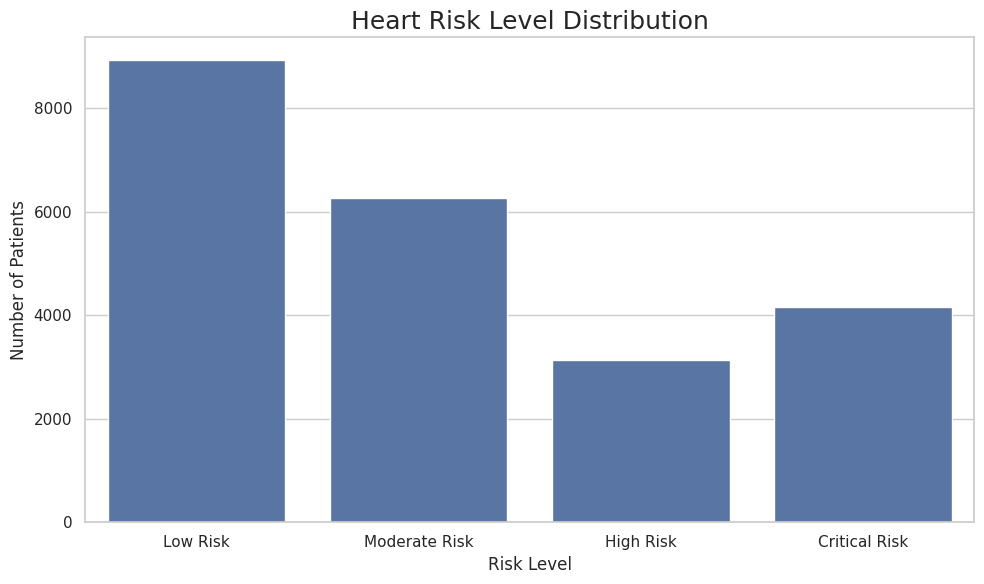

In [16]:
plt.figure(figsize=(10, 6))

order = [
    "Low Risk",
    "Moderate Risk",
    "High Risk",
    "Critical Risk"
]

sns.countplot(
    data=df,
    x="risk_level",
    order=order
)

plt.title(
    "Heart Risk Level Distribution",
    fontsize=18
)

plt.xlabel("Risk Level")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

In [17]:
df = df.copy()

# Remove duplicate records
df = df.drop_duplicates()

# Remove duplicate patient IDs
df = df.drop_duplicates(
    subset=["patient_id"]
)

# Convert numeric columns
numeric_columns = [
    "age",
    "heart_rate",
    "systolic_blood_pressure",
    "oxygen_saturation",
    "chest_pain_severity",
    "body_temperature"
]

for column in numeric_columns:

    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

# Clean categorical columns
categorical_columns = [
    "gender",
    "smoker_status",
    "diabetes_history",
    "risk_level"
]

for column in categorical_columns:

    df[column] = (
        df[column]
        .astype("string")
        .str.strip()
    )

print(
    "Dataset after cleaning:",
    df.shape
)

Dataset after cleaning: (22500, 11)


In [18]:
print("Age range:")
print(
    df["age"].min(),
    "to",
    df["age"].max()
)

print("\nHeart rate range:")
print(
    df["heart_rate"].min(),
    "to",
    df["heart_rate"].max()
)

print("\nBlood pressure range:")
print(
    df["systolic_blood_pressure"].min(),
    "to",
    df["systolic_blood_pressure"].max()
)

print("\nOxygen saturation range:")
print(
    df["oxygen_saturation"].min(),
    "to",
    df["oxygen_saturation"].max()
)

print("\nChest pain severity range:")
print(
    df["chest_pain_severity"].min(),
    "to",
    df["chest_pain_severity"].max()
)

print("\nBody temperature range:")
print(
    df["body_temperature"].min(),
    "to",
    df["body_temperature"].max()
)

Age range:
18 to 92

Heart rate range:
36 to 174

Blood pressure range:
72 to 225

Oxygen saturation range:
76.0 to 100.0

Chest pain severity range:
0.0 to 10.0

Body temperature range:
35.1 to 39.1


In [19]:
display(
    df[
        numeric_columns
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
age,22500.0,59.067778,18.729212,18.0,45.0,61.0,74.0,92.0
heart_rate,22500.0,90.530222,21.418896,36.0,74.0,87.0,104.0,174.0
systolic_blood_pressure,22500.0,153.380267,27.014243,72.0,132.0,158.0,174.0,225.0
oxygen_saturation,22500.0,93.568880,5.052325,76.0,91.0,95.2,97.4,100.0
chest_pain_severity,22500.0,3.293822,2.578688,0.0,1.1,2.7,5.4,10.0
body_temperature,22500.0,36.925711,0.424039,35.1,36.6,36.9,37.2,39.1


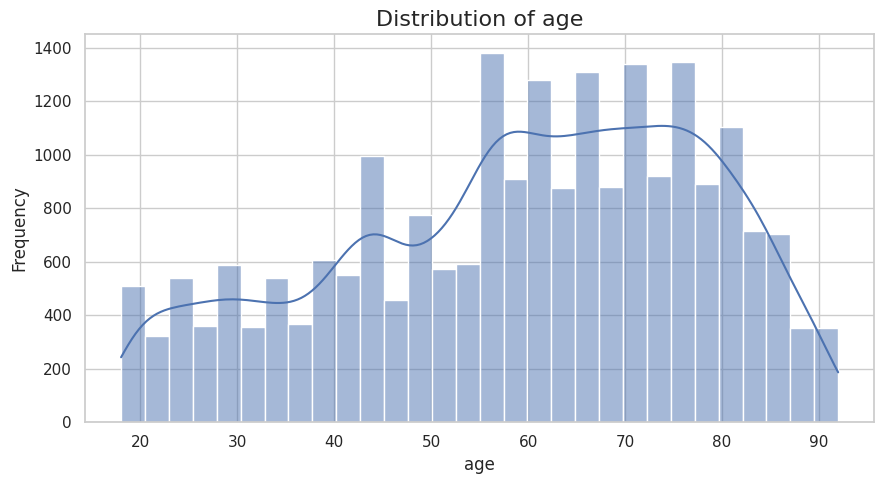

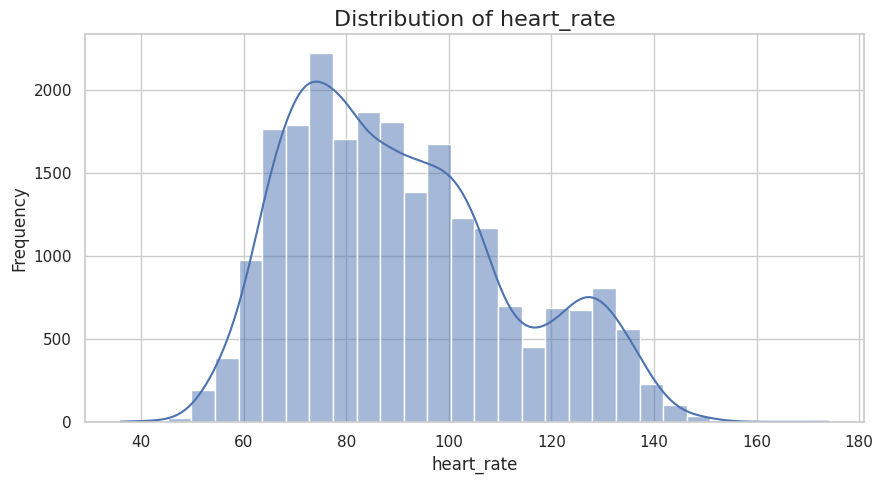

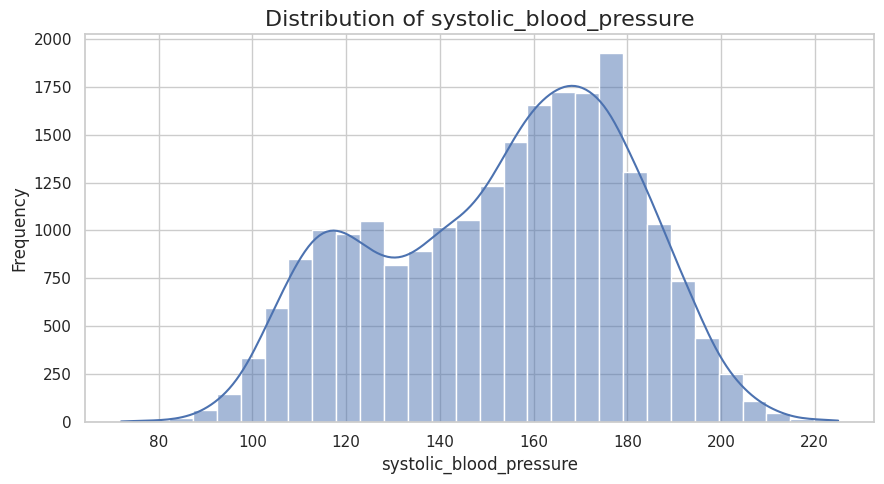

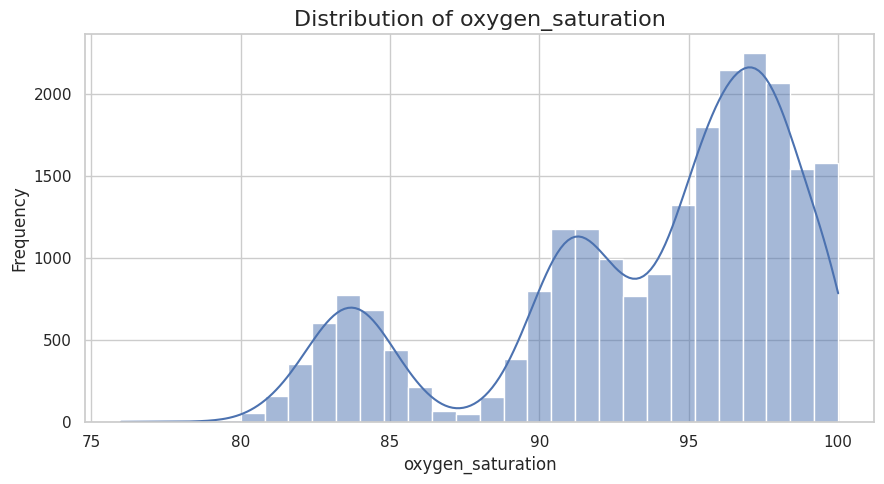

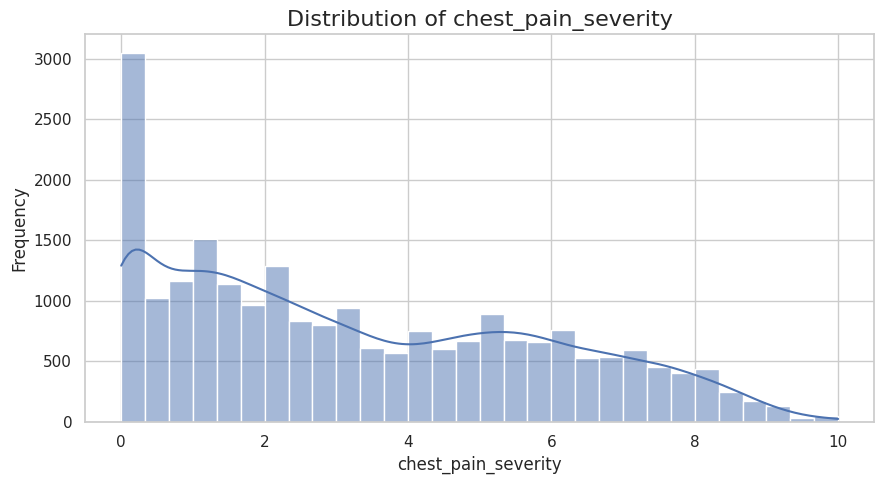

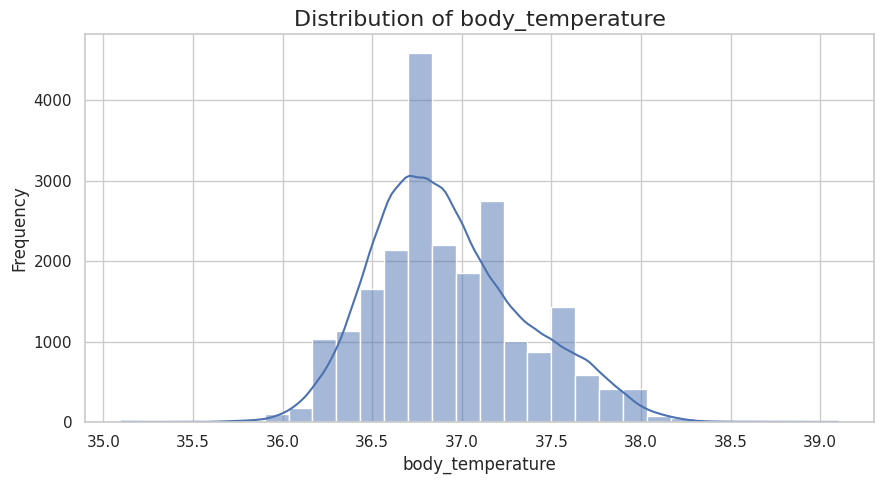

In [20]:
for column in numeric_columns:

    plt.figure(
        figsize=(9, 5)
    )

    sns.histplot(
        data=df,
        x=column,
        kde=True,
        bins=30
    )

    plt.title(
        f"Distribution of {column}",
        fontsize=16
    )

    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

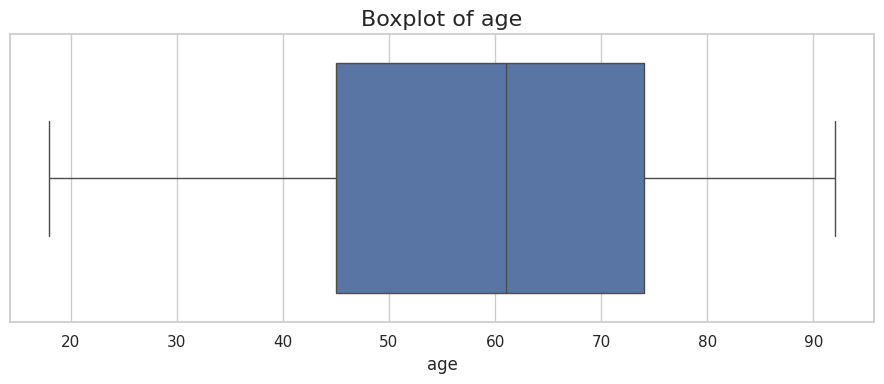

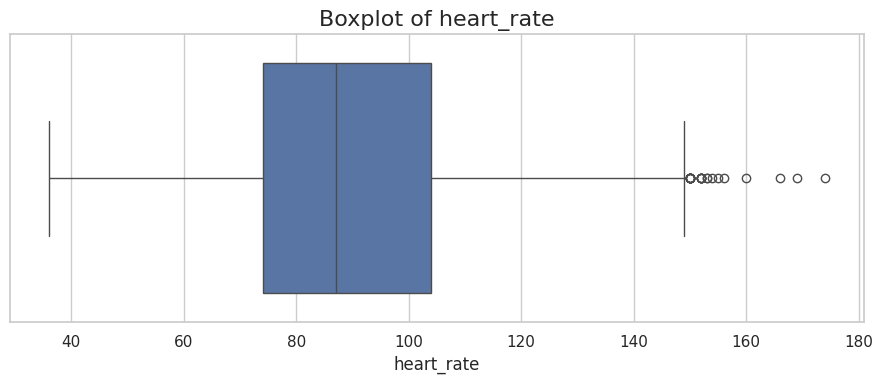

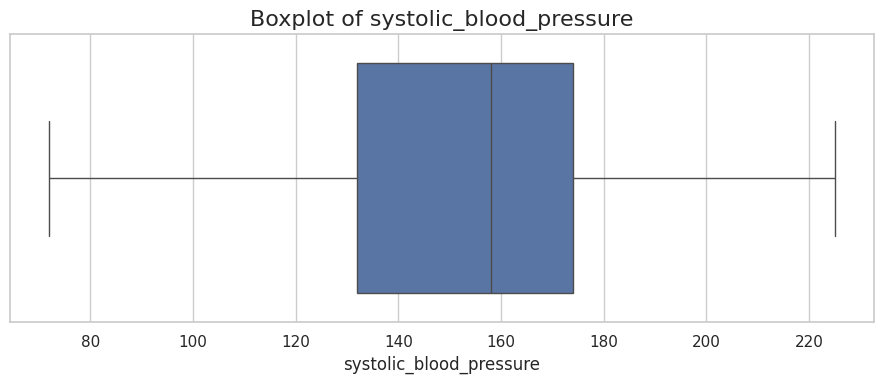

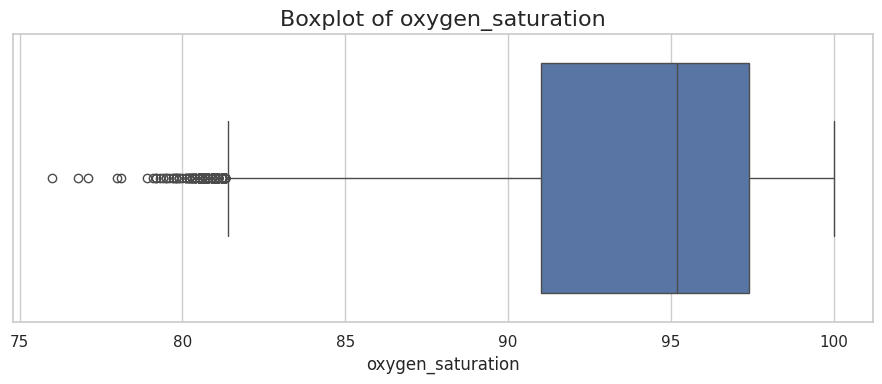

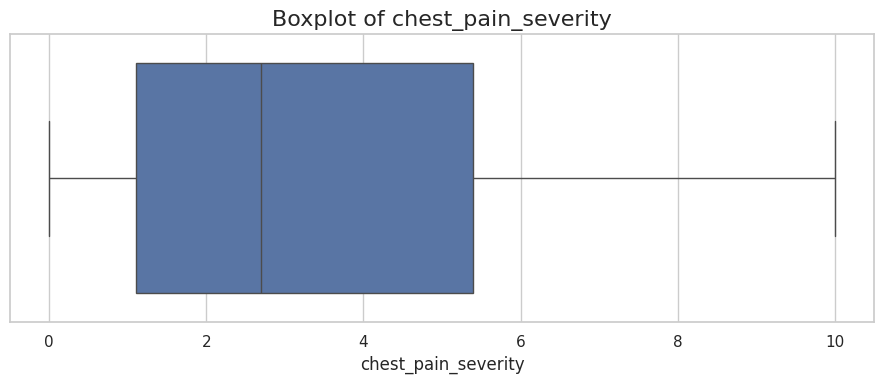

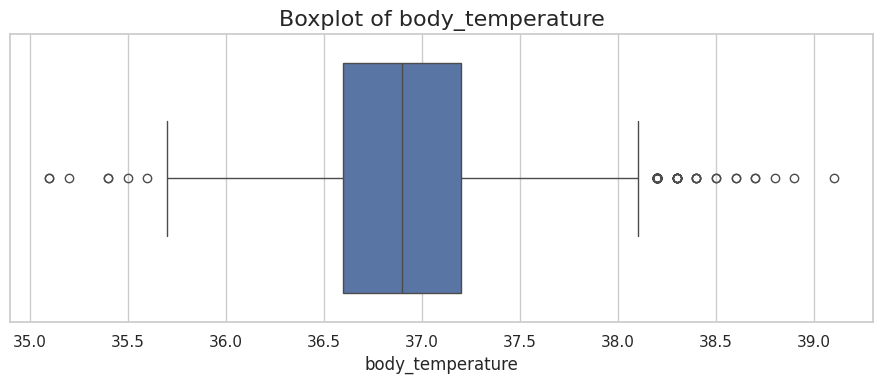

In [21]:
for column in numeric_columns:

    plt.figure(
        figsize=(9, 4)
    )

    sns.boxplot(
        x=df[column]
    )

    plt.title(
        f"Boxplot of {column}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

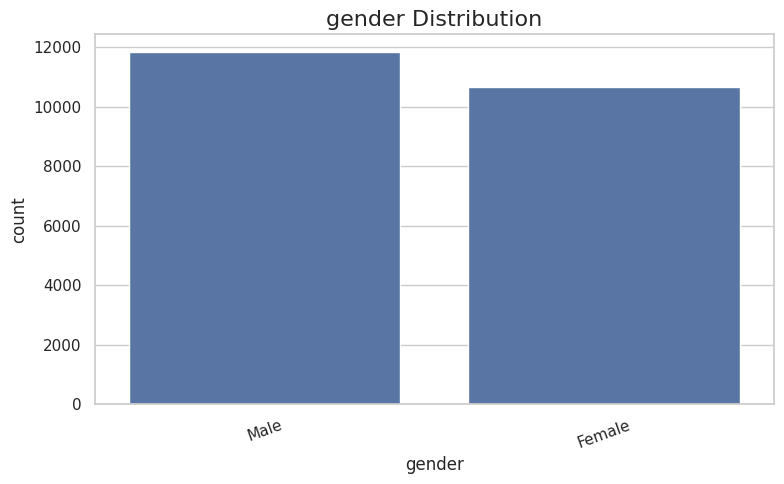

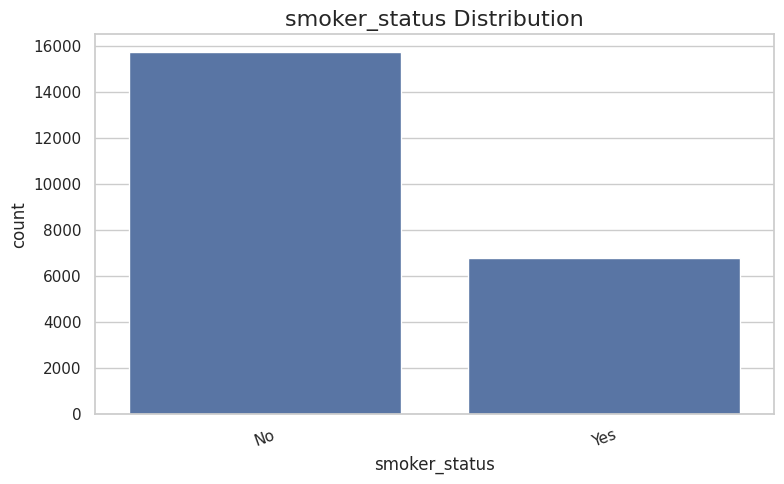

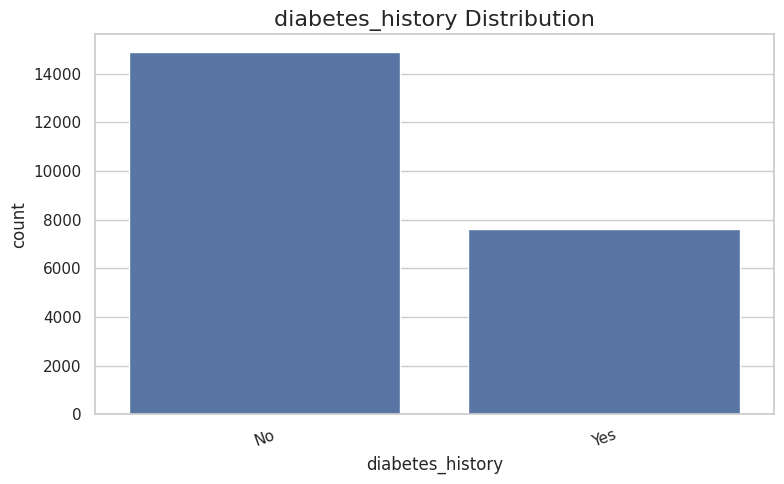

In [22]:
categorical_features = [
    "gender",
    "smoker_status",
    "diabetes_history"
]

for column in categorical_features:

    plt.figure(
        figsize=(8, 5)
    )

    sns.countplot(
        data=df,
        x=column
    )

    plt.title(
        f"{column} Distribution",
        fontsize=16
    )

    plt.xticks(
        rotation=20
    )

    plt.tight_layout()
    plt.show()

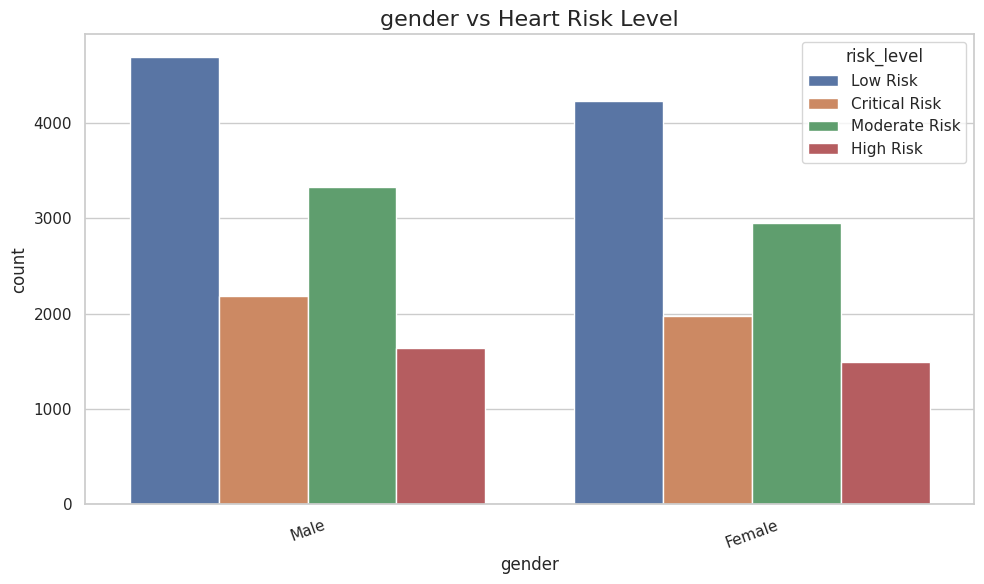

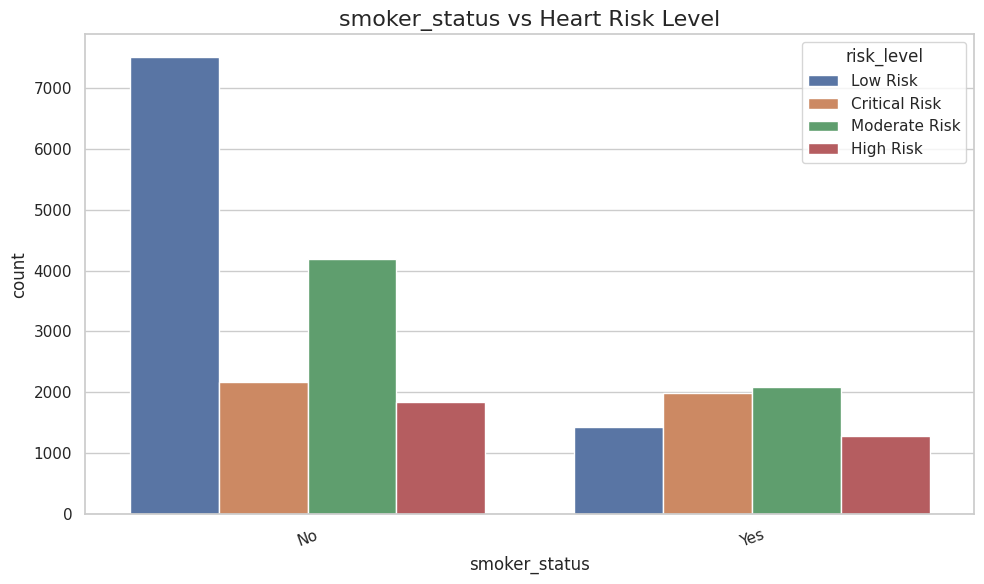

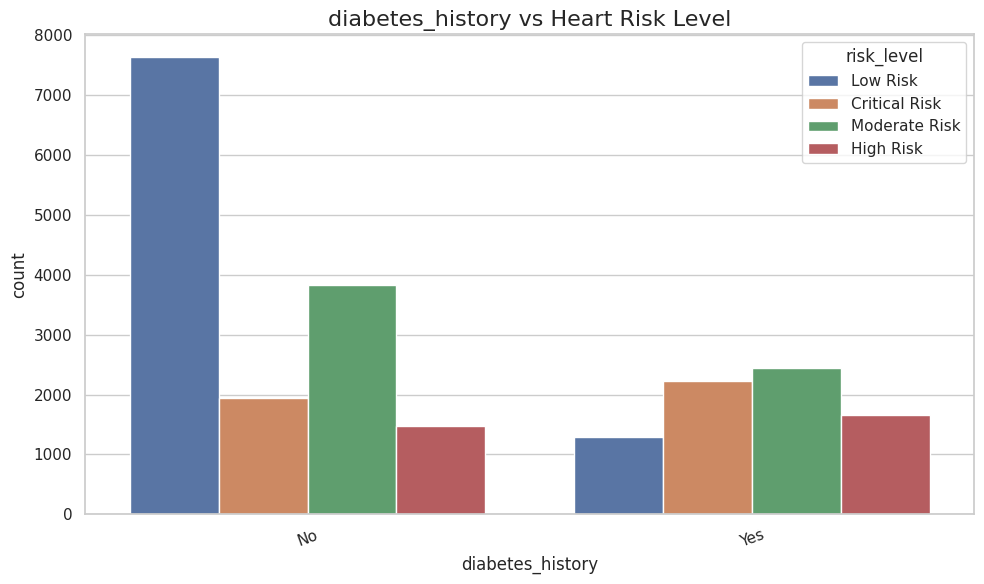

In [23]:
for column in categorical_features:

    plt.figure(
        figsize=(10, 6)
    )

    sns.countplot(
        data=df,
        x=column,
        hue="risk_level",
        order=df[column].value_counts().index
    )

    plt.title(
        f"{column} vs Heart Risk Level",
        fontsize=16
    )

    plt.xticks(
        rotation=20
    )

    plt.tight_layout()
    plt.show()

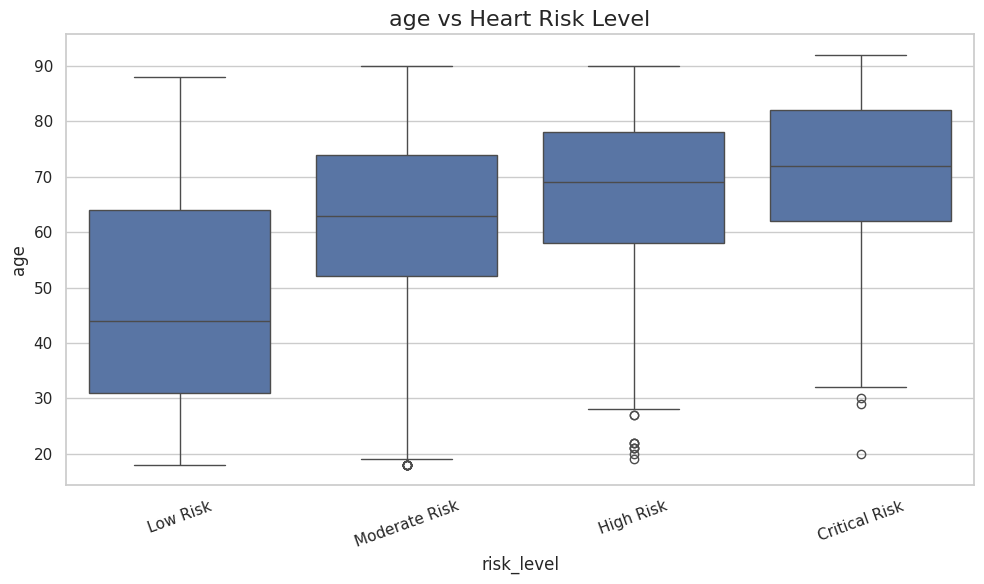

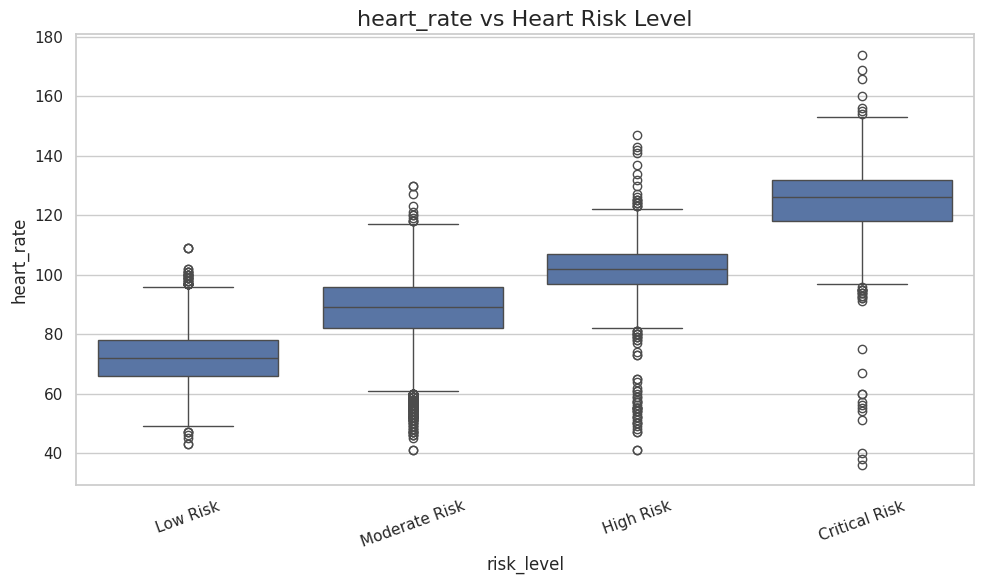

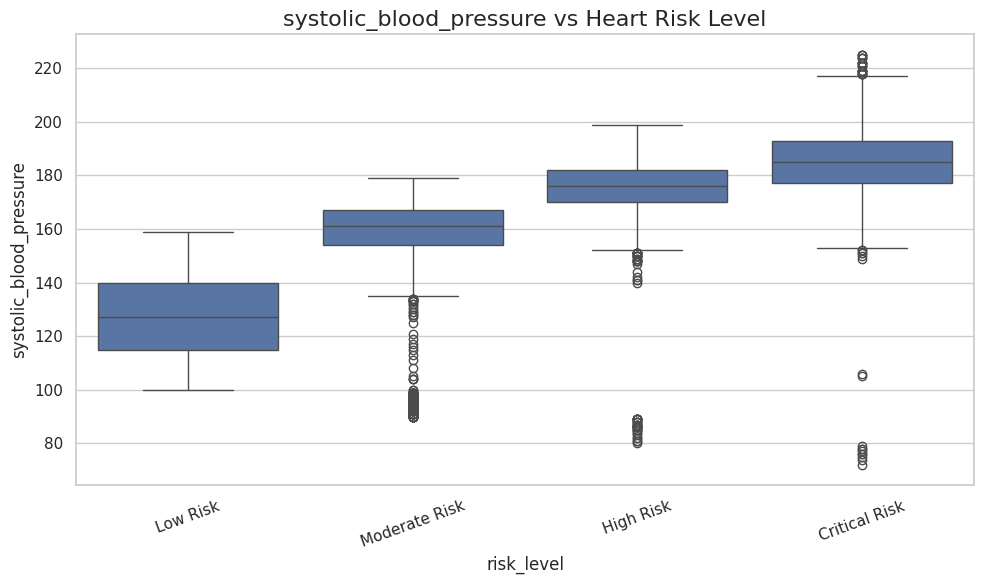

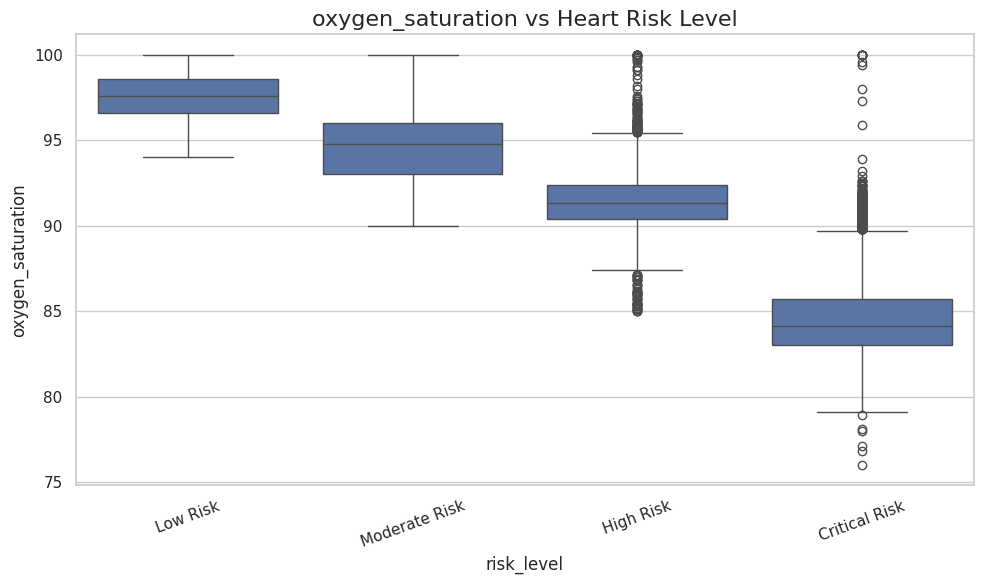

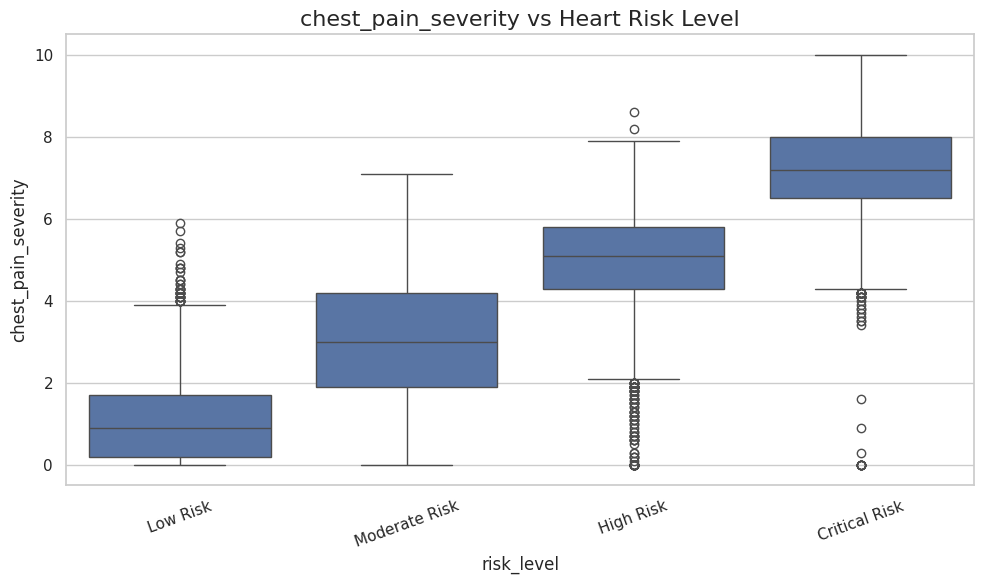

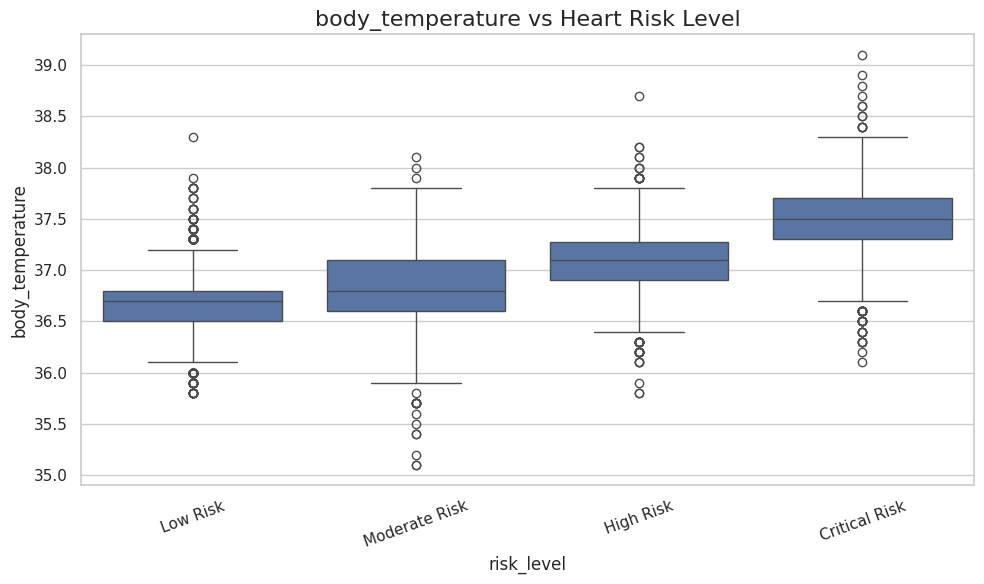

In [24]:
for column in numeric_columns:

    plt.figure(
        figsize=(10, 6)
    )

    sns.boxplot(
        data=df,
        x="risk_level",
        y=column,
        order=order
    )

    plt.title(
        f"{column} vs Heart Risk Level",
        fontsize=16
    )

    plt.xticks(
        rotation=20
    )

    plt.tight_layout()
    plt.show()

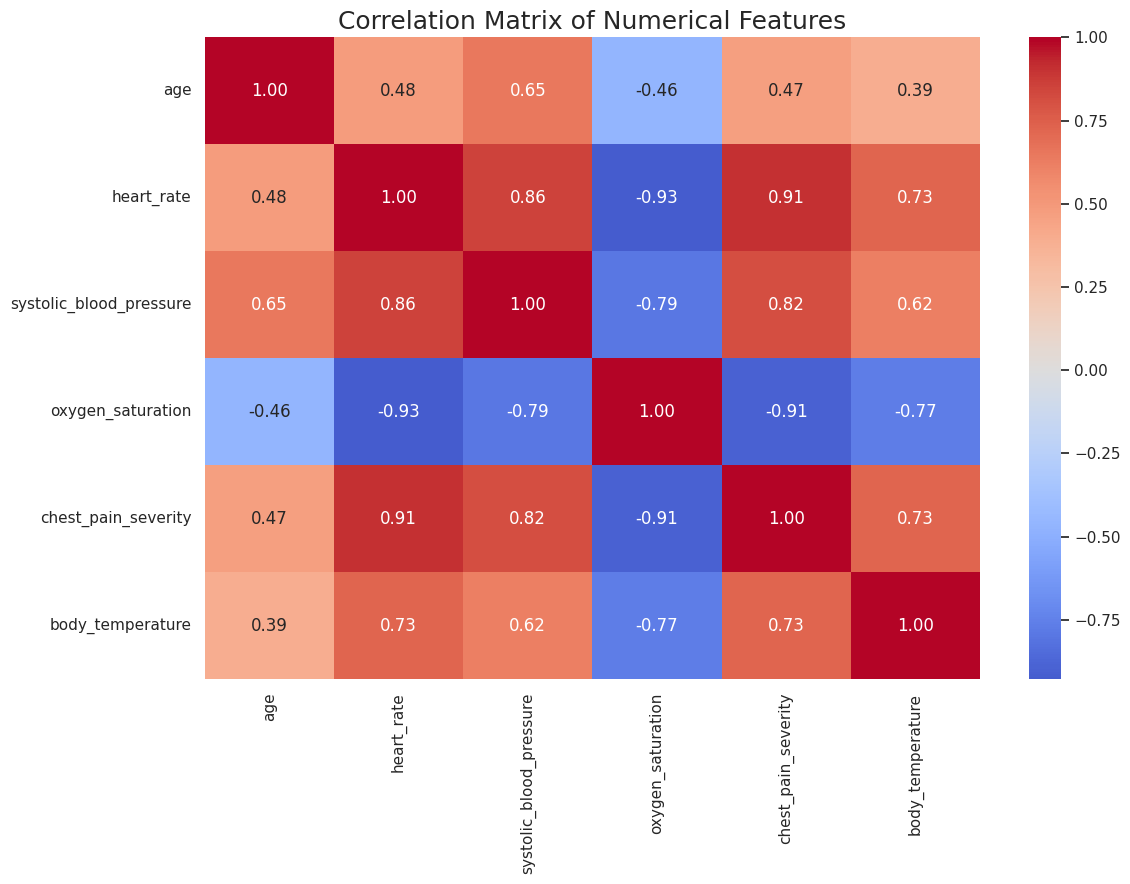

In [25]:
plt.figure(
    figsize=(12, 9)
)

correlation_matrix = df[
    numeric_columns
].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Correlation Matrix of Numerical Features",
    fontsize=18
)

plt.tight_layout()
plt.show()

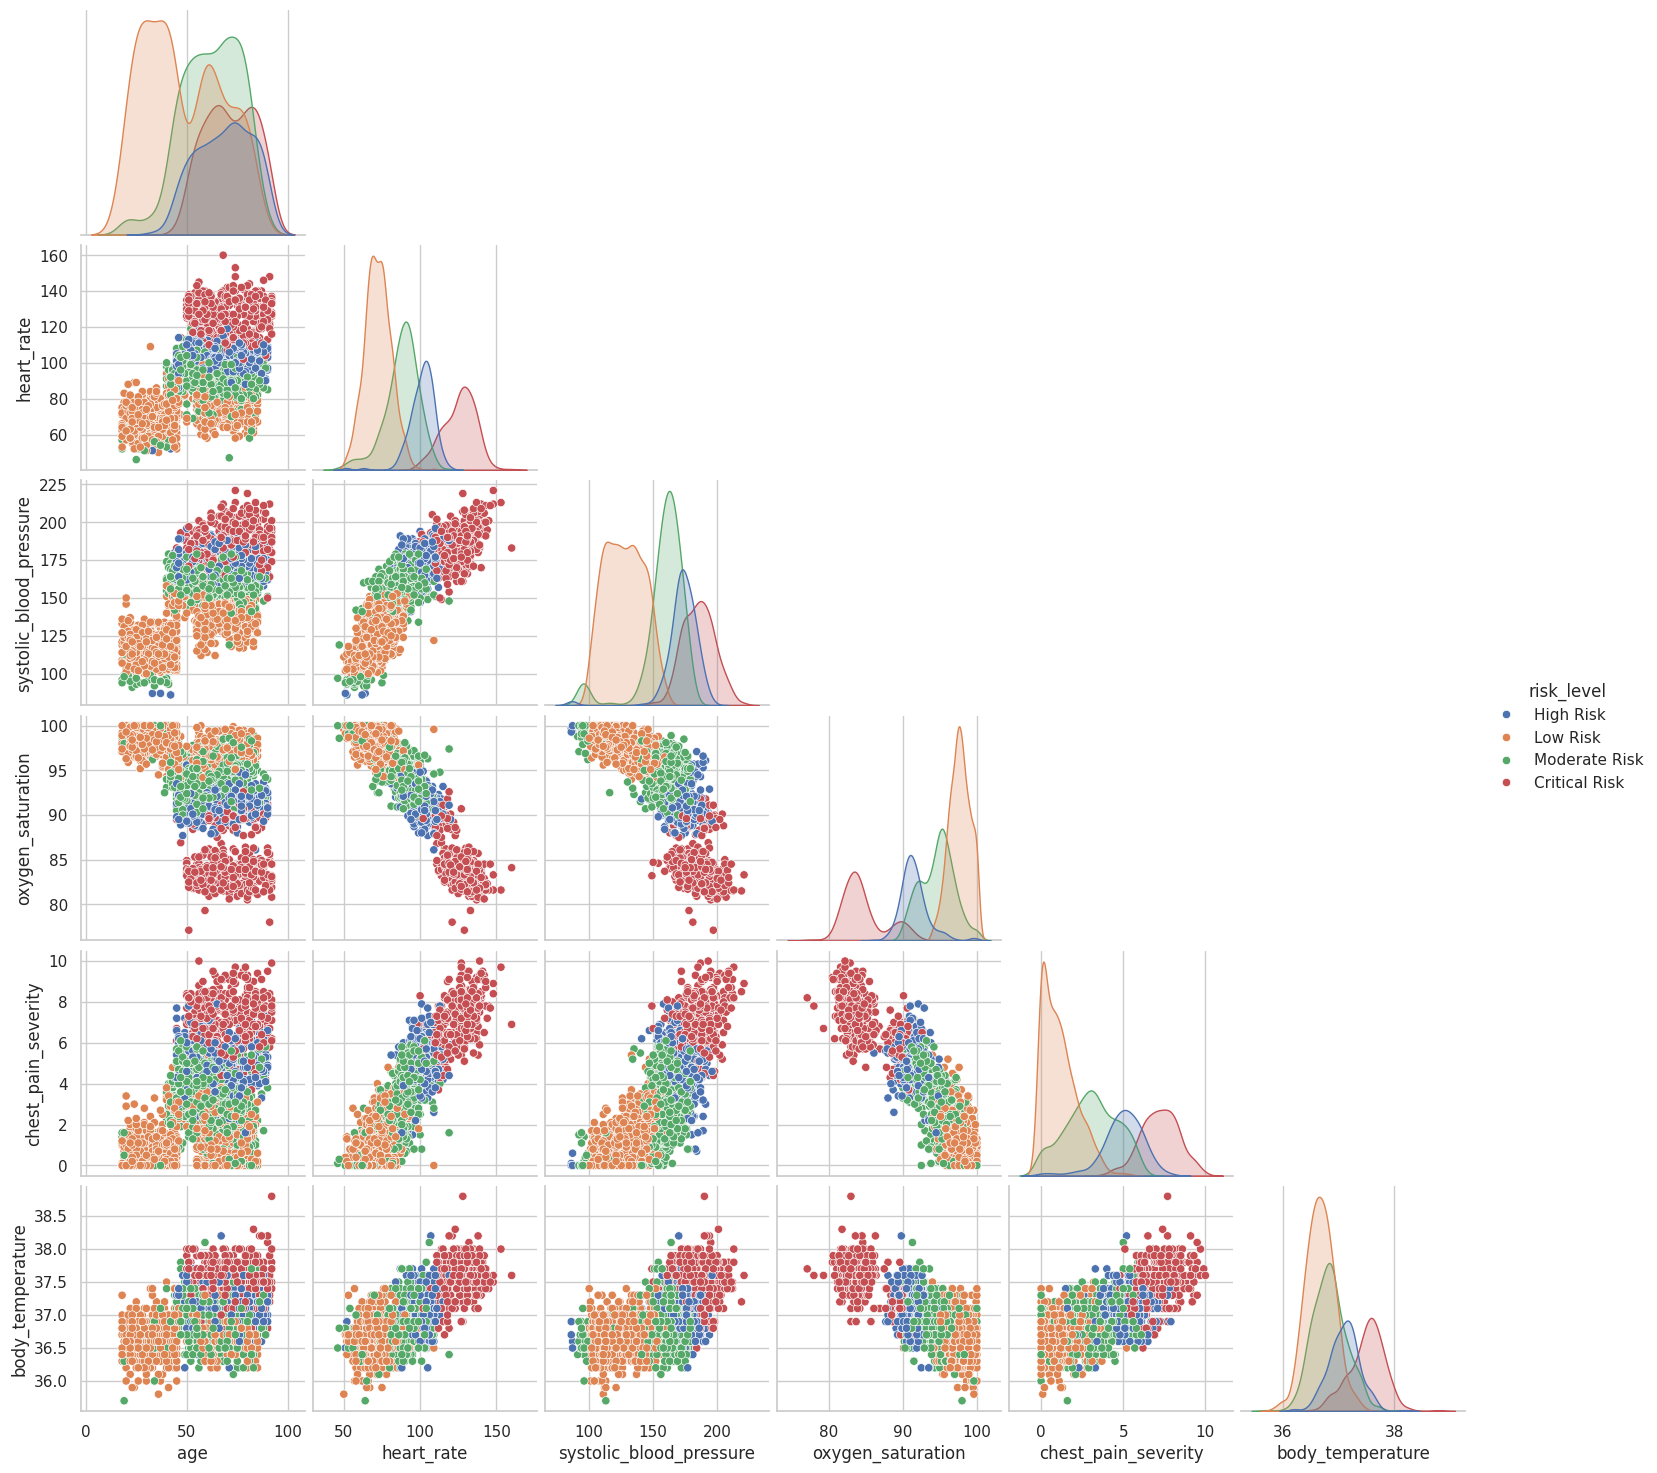

In [26]:
sample_df = df.sample(
    min(2000, len(df)),
    random_state=42
)

sns.pairplot(
    sample_df[
        numeric_columns[:]
        + ["risk_level"]
    ],
    hue="risk_level",
    corner=True
)

plt.show()

In [27]:
df["pulse_pressure"] = (
    df["systolic_blood_pressure"]
)

df["age_group"] = pd.cut(
    df["age"],
    bins=[
        0,
        30,
        45,
        60,
        75,
        120
    ],
    labels=[
        "Young",
        "Adult",
        "Middle_Aged",
        "Senior",
        "Elderly"
    ]
)

df["heart_rate_flag"] = pd.cut(
    df["heart_rate"],
    bins=[
        -np.inf,
        60,
        100,
        np.inf
    ],
    labels=[
        "Low",
        "Normal",
        "High"
    ]
)

df["oxygen_flag"] = pd.cut(
    df["oxygen_saturation"],
    bins=[
        -np.inf,
        94,
        98,
        np.inf
    ],
    labels=[
        "Low",
        "Normal",
        "High"
    ]
)

print(
    df[
        [
            "age_group",
            "heart_rate_flag",
            "oxygen_flag"
        ]
    ].head()
)

     age_group heart_rate_flag oxygen_flag
0        Adult          Normal        High
1  Middle_Aged          Normal      Normal
2  Middle_Aged            High         Low
3      Elderly          Normal      Normal
4  Middle_Aged          Normal      Normal


In [28]:
FEATURES = [
    "age",
    "gender",
    "smoker_status",
    "diabetes_history",
    "heart_rate",
    "systolic_blood_pressure",
    "oxygen_saturation",
    "chest_pain_severity",
    "body_temperature",
    "age_group",
    "heart_rate_flag",
    "oxygen_flag"
]

TARGET = "risk_level"

X = df[FEATURES].copy()

y = df[TARGET].copy()

print(
    "Features:",
    FEATURES
)

print(
    "\nTarget:",
    TARGET
)

print(
    "\nX shape:",
    X.shape
)

print(
    "y shape:",
    y.shape
)

Features: ['age', 'gender', 'smoker_status', 'diabetes_history', 'heart_rate', 'systolic_blood_pressure', 'oxygen_saturation', 'chest_pain_severity', 'body_temperature', 'age_group', 'heart_rate_flag', 'oxygen_flag']

Target: risk_level

X shape: (22500, 12)
y shape: (22500,)


In [29]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=RANDOM_STATE,

    stratify=y
)

print(
    "Training samples:",
    X_train.shape[0]
)

print(
    "Testing samples:",
    X_test.shape[0]
)

print("\nTraining distribution:")
display(
    y_train.value_counts(
        normalize=True
    ).mul(100).round(2)
)

print("\nTesting distribution:")
display(
    y_test.value_counts(
        normalize=True
    ).mul(100).round(2)
)

Training samples: 18000
Testing samples: 4500

Training distribution:


,proportion
risk_level,
Low Risk,39.68
Moderate Risk,27.88
Critical Risk,18.5
High Risk,13.94



Testing distribution:


,proportion
risk_level,
Low Risk,39.67
Moderate Risk,27.87
Critical Risk,18.51
High Risk,13.96


In [30]:
numeric_features = [
    "age",
    "heart_rate",
    "systolic_blood_pressure",
    "oxygen_saturation",
    "chest_pain_severity",
    "body_temperature"
]

categorical_features = [
    "gender",
    "smoker_status",
    "diabetes_history",
    "age_group",
    "heart_rate_flag",
    "oxygen_flag"
]

numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),

    (
        "scaler",
        StandardScaler()
    )
])

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="most_frequent"
        )
    ),

    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

preprocessor = ColumnTransformer([

    (
        "numeric",
        numeric_pipeline,
        numeric_features
    ),

    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

print(
    "Preprocessing pipeline created."
)

Preprocessing pipeline created.


In [31]:
models = {

    "Random Forest": RandomForestClassifier(
        n_estimators=400,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=400,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

In [32]:
model_results = []

trained_pipelines = {}

for name, model in models.items():

    print(
        f"\nTraining {name}..."
    )

    pipeline = Pipeline([

        (
            "preprocessor",
            preprocessor
        ),

        (
            "model",
            model
        )
    ])

    pipeline.fit(
        X_train,
        y_train
    )

    predictions = pipeline.predict(
        X_test
    )

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    model_results.append({

        "Model": name,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1 Score": f1
    })

    trained_pipelines[name] = pipeline


model_results_df = pd.DataFrame(
    model_results
).sort_values(
    "F1 Score",
    ascending=False
)

display(
    model_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)


Training Random Forest...

Training Extra Trees...

Training Gradient Boosting...


,Model,Accuracy,Precision,Recall,F1 Score
2,Gradient Boosting,0.9691,0.9693,0.9691,0.9692
0,Random Forest,0.9629,0.9633,0.9629,0.9630
1,Extra Trees,0.9158,0.9156,0.9158,0.9156


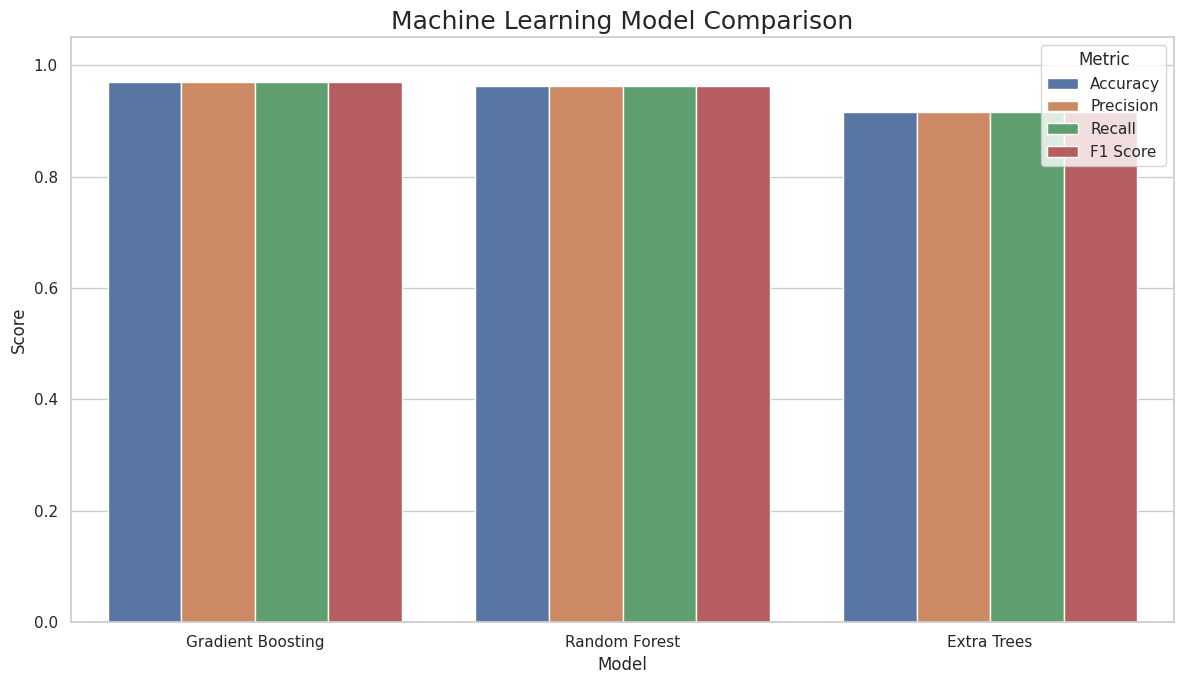

In [33]:
plot_df = model_results_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(
    figsize=(12, 7)
)

sns.barplot(
    data=plot_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.ylim(
    0,
    1.05
)

plt.title(
    "Machine Learning Model Comparison",
    fontsize=18
)

plt.ylabel(
    "Score"
)

plt.tight_layout()
plt.show()

In [34]:
best_model_name = (
    model_results_df
    .iloc[0]["Model"]
)

best_model = trained_pipelines[
    best_model_name
]

print(
    "Best model:",
    best_model_name
)

Best model: Gradient Boosting


In [35]:
rf_pipeline = Pipeline([

    (
        "preprocessor",
        preprocessor
    ),

    (
        "model",
        RandomForestClassifier(
            random_state=42,
            n_jobs=-1,
            class_weight="balanced"
        )
    )
])

rf_parameters = {

    "model__n_estimators": [
        300,
        500,
        700,
        1000
    ],

    "model__max_depth": [
        None,
        10,
        15,
        20,
        30
    ],

    "model__min_samples_split": [
        2,
        5,
        10
    ],

    "model__min_samples_leaf": [
        1,
        2,
        4
    ],

    "model__max_features": [
        "sqrt",
        "log2",
        0.7,
        1.0
    ]
}

In [41]:
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# --------------------------------------------------
# FAST HYPERPARAMETER TUNING
# --------------------------------------------------

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Keep a reasonably strong Random Forest
rf_pipeline_fast = Pipeline([
    ("preprocessor", preprocessor),

    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1,
        class_weight="balanced",
        n_estimators=400
    ))
])

# Small, sensible search space
rf_parameters_fast = {
    "model__max_depth": [
        None,
        15,
        25
    ],

    "model__min_samples_split": [
        2,
        5
    ],

    "model__min_samples_leaf": [
        1,
        2
    ],

    "model__max_features": [
        "sqrt",
        "log2"
    ]
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline_fast,

    param_distributions=rf_parameters_fast,

    # Only 8 combinations instead of 30
    n_iter=8,

    # 3-fold instead of 5-fold
    cv=cv,

    scoring="f1_weighted",

    random_state=42,

    n_jobs=-1,

    verbose=1,

    return_train_score=False
)

print("Starting fast hyperparameter tuning...")

rf_search.fit(
    X_train,
    y_train
)

tuned_model = rf_search.best_estimator_

print("\n======================================")
print("FAST TUNING COMPLETED")
print("======================================")

print(
    "Best CV F1:",
    round(rf_search.best_score_, 4)
)

print("\nBest parameters:")

for parameter, value in rf_search.best_params_.items():
    print(f"{parameter}: {value}")

Starting fast hyperparameter tuning...
Fitting 3 folds for each of 8 candidates, totalling 24 fits

FAST TUNING COMPLETED
Best CV F1: 0.9579

Best parameters:
model__min_samples_split: 2
model__min_samples_leaf: 1
model__max_features: sqrt
model__max_depth: 25


In [42]:
tuned_predictions = (
    tuned_model.predict(X_test)
)

accuracy = accuracy_score(
    y_test,
    tuned_predictions
)

precision = precision_score(
    y_test,
    tuned_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test,
    tuned_predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test,
    tuned_predictions,
    average="weighted",
    zero_division=0
)

print("=" * 60)

print(
    f"Accuracy  : {accuracy:.4f} "
    f"({accuracy*100:.2f}%)"
)

print(
    f"Precision : {precision:.4f} "
    f"({precision*100:.2f}%)"
)

print(
    f"Recall    : {recall:.4f} "
    f"({recall*100:.2f}%)"
)

print(
    f"F1 Score  : {f1:.4f} "
    f"({f1*100:.2f}%)"
)

print("=" * 60)

Accuracy  : 0.9624 (96.24%)
Precision : 0.9628 (96.28%)
Recall    : 0.9624 (96.24%)
F1 Score  : 0.9626 (96.26%)


In [43]:
print(
    classification_report(
        y_test,
        tuned_predictions,
        labels=order,
        target_names=order,
        digits=4,
        zero_division=0
    )
)

               precision    recall  f1-score   support

     Low Risk     0.9805    0.9838    0.9821      1785
Moderate Risk     0.9573    0.9466    0.9519      1254
    High Risk     0.9008    0.9395    0.9197       628
Critical Risk     0.9803    0.9580    0.9690       833

     accuracy                         0.9624      4500
    macro avg     0.9547    0.9569    0.9557      4500
 weighted avg     0.9628    0.9624    0.9626      4500



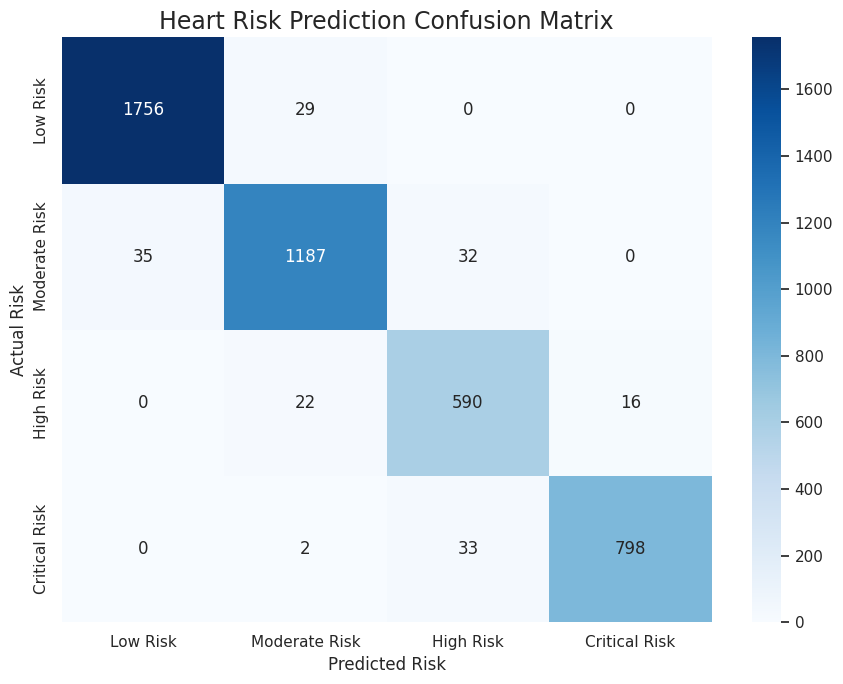

In [44]:
cm = confusion_matrix(
    y_test,
    tuned_predictions,
    labels=order
)

plt.figure(
    figsize=(9, 7)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=order,
    yticklabels=order
)

plt.xlabel(
    "Predicted Risk"
)

plt.ylabel(
    "Actual Risk"
)

plt.title(
    "Heart Risk Prediction Confusion Matrix",
    fontsize=17
)

plt.tight_layout()
plt.show()

In [45]:
report = classification_report(
    y_test,
    tuned_predictions,
    labels=order,
    output_dict=True,
    zero_division=0
)

class_metrics = pd.DataFrame(
    report
).T

display(
    class_metrics
)

,precision,recall,f1-score,support
Low Risk,0.980458,0.983754,0.982103,1785.000000
Moderate Risk,0.957258,0.946571,0.951885,1254.000000
High Risk,0.900763,0.939490,0.919719,628.000000
Critical Risk,0.980344,0.957983,0.969035,833.000000
accuracy,0.962444,0.962444,0.962444,0.962444
macro avg,0.954706,0.956950,0.955685,4500.000000
weighted avg,0.962850,0.962444,0.962557,4500.000000


In [46]:
y_probability = (
    tuned_model.predict_proba(X_test)
)

roc_auc = roc_auc_score(
    y_test,
    y_probability,
    multi_class="ovr",
    average="weighted"
)

print(
    "Weighted Multiclass ROC-AUC:",
    round(roc_auc, 4)
)

Weighted Multiclass ROC-AUC: 0.9974


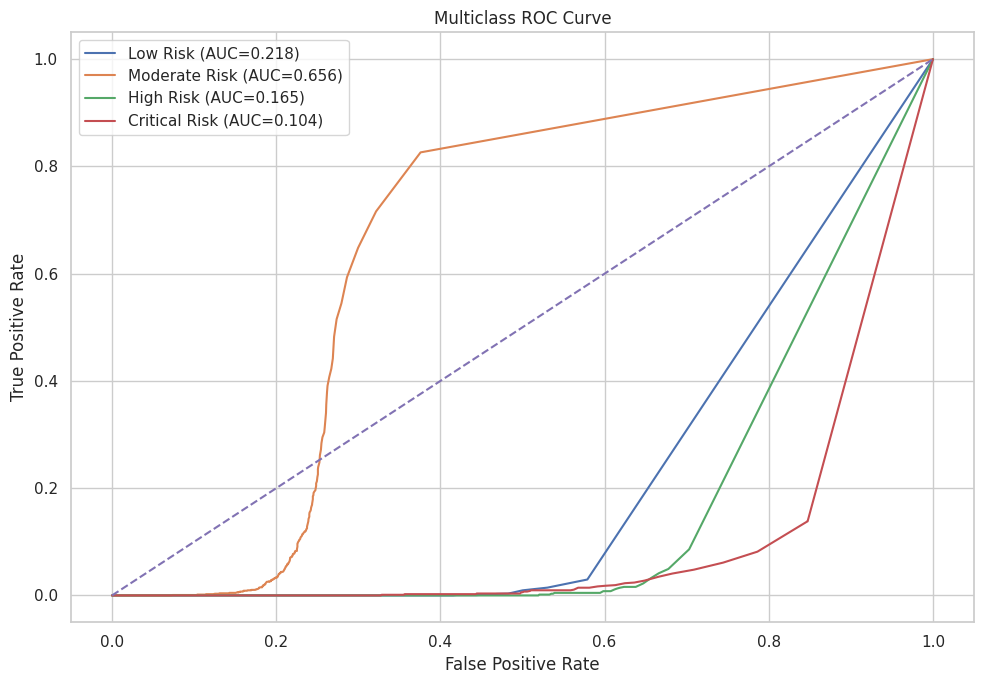

In [47]:
from sklearn.preprocessing import label_binarize

y_test_binary = label_binarize(
    y_test,
    classes=order
)

plt.figure(
    figsize=(10, 7)
)

for i, class_name in enumerate(order):

    fpr, tpr, _ = roc_curve(
        y_test_binary[:, i],
        y_probability[:, i]
    )

    roc_auc_class = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC={roc_auc_class:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Multiclass ROC Curve"
)

plt.legend()

plt.tight_layout()
plt.show()

In [48]:
cv_scores_accuracy = cross_val_score(

    tuned_model,

    X_train,

    y_train,

    cv=cv,

    scoring="accuracy",

    n_jobs=-1
)

cv_scores_f1 = cross_val_score(

    tuned_model,

    X_train,

    y_train,

    cv=cv,

    scoring="f1_weighted",

    n_jobs=-1
)

print(
    "5-Fold Accuracy:"
)

print(
    np.round(
        cv_scores_accuracy,
        4
    )
)

print(
    "\nMean CV Accuracy:",
    round(
        cv_scores_accuracy.mean(),
        4
    )
)

print(
    "\n5-Fold F1:"
)

print(
    np.round(
        cv_scores_f1,
        4
    )
)

print(
    "\nMean CV F1:",
    round(
        cv_scores_f1.mean(),
        4
    )
)

5-Fold Accuracy:
[0.9567 0.9617 0.9553]

Mean CV Accuracy: 0.9579

5-Fold F1:
[0.9567 0.9617 0.9554]

Mean CV F1: 0.9579


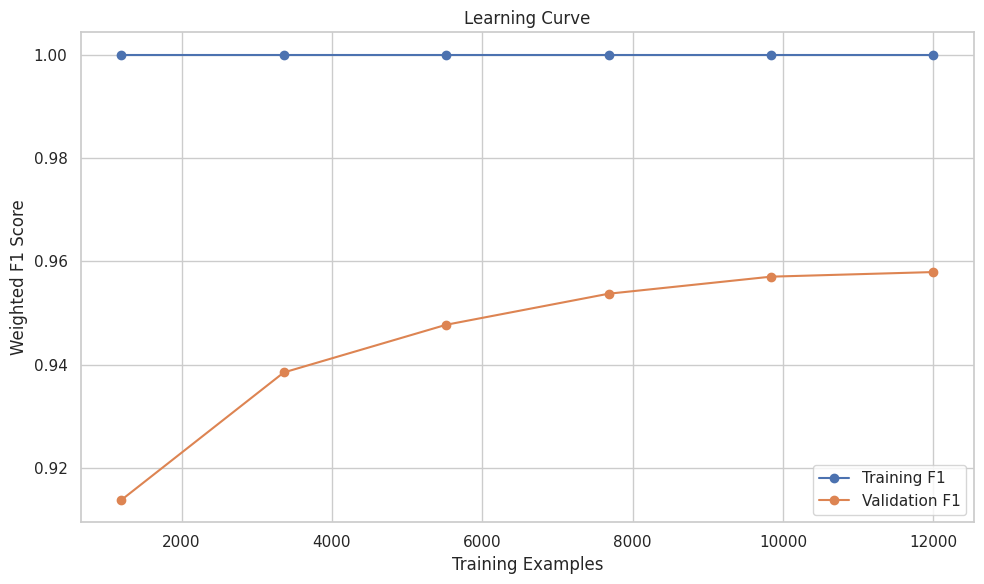

In [49]:
train_sizes, train_scores, validation_scores = (
    learning_curve(

        tuned_model,

        X_train,

        y_train,

        cv=cv,

        scoring="f1_weighted",

        train_sizes=np.linspace(
            0.1,
            1.0,
            6
        ),

        n_jobs=-1
    )
)

train_mean = (
    train_scores.mean(axis=1)
)

validation_mean = (
    validation_scores.mean(axis=1)
)

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Training F1"
)

plt.plot(
    train_sizes,
    validation_mean,
    marker="o",
    label="Validation F1"
)

plt.xlabel(
    "Training Examples"
)

plt.ylabel(
    "Weighted F1 Score"
)

plt.title(
    "Learning Curve"
)

plt.legend()

plt.tight_layout()
plt.show()

In [50]:
fitted_preprocessor = (
    tuned_model
    .named_steps["preprocessor"]
)

rf_model = (
    tuned_model
    .named_steps["model"]
)

feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

feature_importances = (
    rf_model.feature_importances_
)

importance_df = pd.DataFrame({

    "Feature": feature_names,

    "Importance": feature_importances

}).sort_values(
    "Importance",
    ascending=False
)

display(
    importance_df.head(20)
)

,Feature,Importance
2,numeric__systolic_blood_pressure,0.251978
3,numeric__oxygen_saturation,0.185424
1,numeric__heart_rate,0.135846
4,numeric__chest_pain_severity,0.122689
21,categorical__oxygen_flag_Low,0.054333
0,numeric__age,0.050160
5,numeric__body_temperature,0.039055
17,categorical__heart_rate_flag_High,0.036805
19,categorical__heart_rate_flag_Normal,0.028713
22,categorical__oxygen_flag_Normal,0.014116


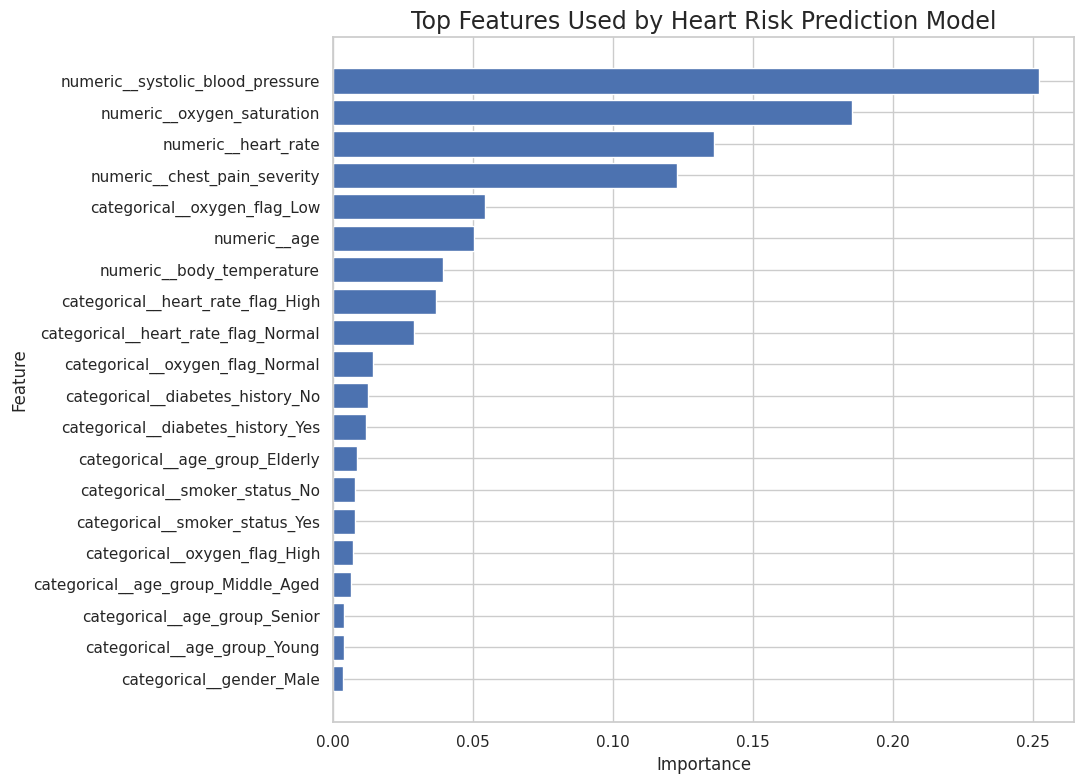

In [51]:
top_features = (
    importance_df
    .head(20)
    .sort_values(
        "Importance"
    )
)

plt.figure(
    figsize=(11, 8)
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Top Features Used by Heart Risk Prediction Model",
    fontsize=17
)

plt.tight_layout()
plt.show()

In [52]:
permutation = permutation_importance(

    tuned_model,

    X_test,

    y_test,

    scoring="f1_weighted",

    n_repeats=5,

    random_state=42,

    n_jobs=-1
)

permutation_df = pd.DataFrame({

    "Feature": X_test.columns,

    "Importance":
        permutation.importances_mean

}).sort_values(
    "Importance",
    ascending=False
)

display(
    permutation_df
)

,Feature,Importance
5,systolic_blood_pressure,0.286975
6,oxygen_saturation,0.080298
7,chest_pain_severity,0.057057
11,oxygen_flag,0.053606
3,diabetes_history,0.031824
0,age,0.030653
10,heart_rate_flag,0.025306
2,smoker_status,0.023513
4,heart_rate,0.023025
9,age_group,0.016013


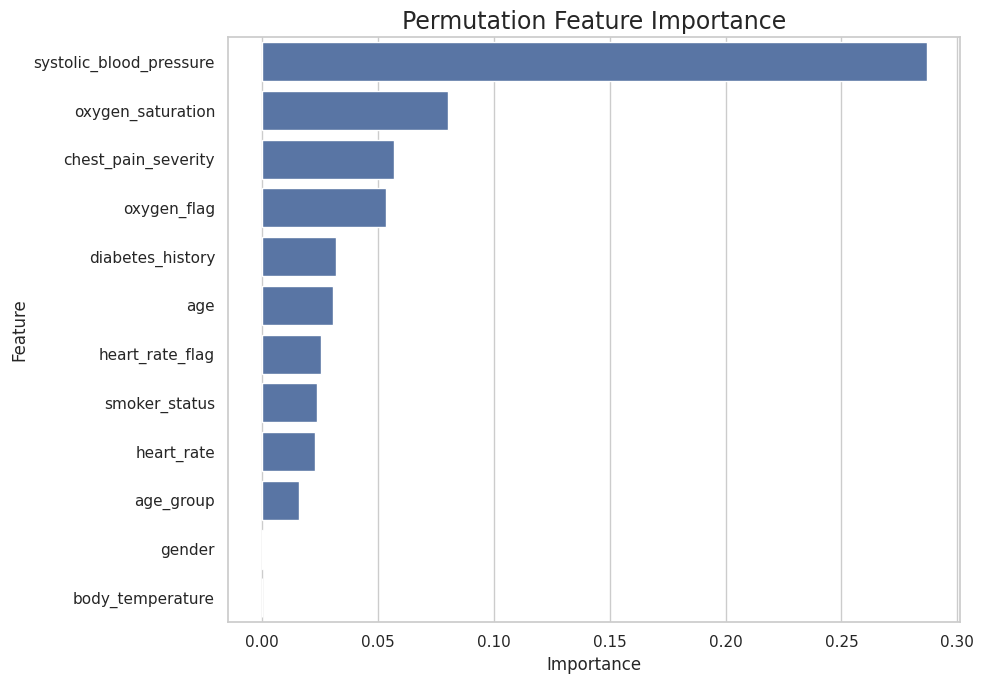

In [53]:
plt.figure(
    figsize=(10, 7)
)

sns.barplot(
    data=permutation_df,
    x="Importance",
    y="Feature"
)

plt.title(
    "Permutation Feature Importance",
    fontsize=17
)

plt.tight_layout()
plt.show()

In [54]:
def generate_recommendations(
    patient,
    risk_level
):

    do_recommendations = []
    avoid_recommendations = []

    # -------------------------
    # GENERAL
    # -------------------------

    do_recommendations.append(
        "Monitor your cardiovascular health regularly."
    )

    do_recommendations.append(
        "Maintain a balanced diet and regular physical activity."
    )

    do_recommendations.append(
        "Follow advice from qualified healthcare professionals."
    )

    avoid_recommendations.append(
        "Do not use this prediction as a medical diagnosis."
    )

    # -------------------------
    # SMOKING
    # -------------------------

    if str(
        patient["smoker_status"]
    ).lower() == "yes":

        do_recommendations.append(
            "Consider a structured smoking-cessation program."
        )

        avoid_recommendations.append(
            "Avoid smoking and exposure to tobacco smoke."
        )

    # -------------------------
    # DIABETES
    # -------------------------

    if str(
        patient["diabetes_history"]
    ).lower() == "yes":

        do_recommendations.append(
            "Keep blood glucose monitoring and diabetes management under medical supervision."
        )

    # -------------------------
    # BLOOD PRESSURE
    # -------------------------

    if patient[
        "systolic_blood_pressure"
    ] >= 140:

        do_recommendations.append(
            "Discuss your elevated blood pressure with a healthcare professional."
        )

        avoid_recommendations.append(
            "Avoid excessive sodium intake unless your clinician advises otherwise."
        )

    # -------------------------
    # OXYGEN
    # -------------------------

    if patient[
        "oxygen_saturation"
    ] < 94:

        do_recommendations.append(
            "Seek prompt medical assessment for low oxygen saturation, particularly if symptoms are present."
        )

    # -------------------------
    # HEART RATE
    # -------------------------

    if (
        patient["heart_rate"] < 50
        or
        patient["heart_rate"] > 120
    ):

        do_recommendations.append(
            "Discuss an unusually high or low resting heart rate with a healthcare professional."
        )

    # -------------------------
    # CHEST PAIN
    # -------------------------

    if patient[
        "chest_pain_severity"
    ] >= 7:

        do_recommendations.append(
            "Severe chest pain requires urgent medical assessment."
        )

        avoid_recommendations.append(
            "Do not delay emergency medical care for severe or worsening chest pain."
        )

    # -------------------------
    # RISK-SPECIFIC GUIDANCE
    # -------------------------

    if risk_level == "Low Risk":

        doctor = (
            "Routine primary-care follow-up may be appropriate. "
            "Continue preventive heart-health practices."
        )

    elif risk_level == "Moderate Risk":

        doctor = (
            "Consider discussing the result and cardiovascular "
            "risk factors with a primary-care physician."
        )

    elif risk_level == "High Risk":

        doctor = (
            "Consider timely evaluation by a physician. "
            "A cardiology consultation may be appropriate depending "
            "on symptoms and clinical history."
        )

    else:

        doctor = (
            "This prediction indicates a potentially serious risk "
            "category. Seek prompt medical evaluation. If severe "
            "chest pain, severe breathing difficulty, fainting, "
            "or other emergency symptoms are present, seek emergency care."
        )

    return {

        "risk_level": risk_level,

        "what_to_do":
            list(dict.fromkeys(
                do_recommendations
            )),

        "what_to_avoid":
            list(dict.fromkeys(
                avoid_recommendations
            )),

        "doctor_guidance":
            doctor
    }

In [55]:
def predict_heart_risk(patient_data):

    required_features = [
        "age",
        "gender",
        "smoker_status",
        "diabetes_history",
        "heart_rate",
        "systolic_blood_pressure",
        "oxygen_saturation",
        "chest_pain_severity",
        "body_temperature"
    ]

    missing = [
        feature
        for feature in required_features
        if feature not in patient_data
    ]

    if missing:

        raise ValueError(
            f"Missing input fields: {missing}"
        )

    patient_df = pd.DataFrame(
        [patient_data]
    )

    # Feature engineering
    patient_df["age_group"] = pd.cut(

        patient_df["age"],

        bins=[
            0,
            30,
            45,
            60,
            75,
            120
        ],

        labels=[
            "Young",
            "Adult",
            "Middle_Aged",
            "Senior",
            "Elderly"
        ]
    )

    patient_df["heart_rate_flag"] = pd.cut(

        patient_df["heart_rate"],

        bins=[
            -np.inf,
            60,
            100,
            np.inf
        ],

        labels=[
            "Low",
            "Normal",
            "High"
        ]
    )

    patient_df["oxygen_flag"] = pd.cut(

        patient_df["oxygen_saturation"],

        bins=[
            -np.inf,
            94,
            98,
            np.inf
        ],

        labels=[
            "Low",
            "Normal",
            "High"
        ]
    )

    patient_features = patient_df[
        FEATURES
    ]

    # Prediction
    prediction = tuned_model.predict(
        patient_features
    )[0]

    probabilities = (
        tuned_model
        .predict_proba(
            patient_features
        )[0]
    )

    classes = (
        tuned_model
        .named_steps["model"]
        .classes_
    )

    confidence = float(
        np.max(probabilities)
    )

    probability_dict = {
        str(cls):
        float(prob)
        for cls, prob
        in zip(
            classes,
            probabilities
        )
    }

    recommendations = (
        generate_recommendations(
            patient_data,
            prediction
        )
    )

    return {

        "prediction":
            str(prediction),

        "confidence":
            round(
                confidence * 100,
                2
            ),

        "probabilities":
            probability_dict,

        "recommendations":
            recommendations
    }

In [56]:
patient = {

    "age": 56,

    "gender": "Female",

    "smoker_status": "No",

    "diabetes_history": "No",

    "heart_rate": 84,

    "systolic_blood_pressure": 146,

    "oxygen_saturation": 95.1,

    "chest_pain_severity": 1.8,

    "body_temperature": 37.1
}

result = predict_heart_risk(
    patient
)

print(
    json.dumps(
        result,
        indent=4
    )
)

{
    "prediction": "Low Risk",
    "confidence": 99.25,
    "probabilities": {
        "Critical Risk": 0.0,
        "High Risk": 0.0,
        "Low Risk": 0.9925,
        "Moderate Risk": 0.0075
    },
    "recommendations": {
        "risk_level": "Low Risk",
        "what_to_do": [
            "Monitor your cardiovascular health regularly.",
            "Maintain a balanced diet and regular physical activity.",
            "Follow advice from qualified healthcare professionals.",
            "Discuss your elevated blood pressure with a healthcare professional."
        ],
        "what_to_avoid": [
            "Do not use this prediction as a medical diagnosis.",
            "Avoid excessive sodium intake unless your clinician advises otherwise."
        ],
        "doctor_guidance": "Routine primary-care follow-up may be appropriate. Continue preventive heart-health practices."
    }
}


In [57]:
MODEL_DIR = Path(
    "/content/heart_risk_models"
)

MODEL_DIR.mkdir(
    exist_ok=True
)

# Save complete pipeline
joblib.dump(
    tuned_model,
    MODEL_DIR /
    "heart_risk_model.pkl"
)

print(
    "Model saved:"
)

print(
    MODEL_DIR /
    "heart_risk_model.pkl"
)

Model saved:
/content/heart_risk_models/heart_risk_model.pkl


In [58]:
metadata = {

    "project":
        "AI-Based Heart Risk Prediction System",

    "dataset":
        "Heart_risk_dataset.csv",

    "target":
        TARGET,

    "features":
        FEATURES,

    "classes":
        order,

    "model":
        "RandomForestClassifier",

    "random_state":
        RANDOM_STATE,

    "test_size":
        0.20,

    "metrics": {

        "accuracy":
            float(accuracy),

        "precision":
            float(precision),

        "recall":
            float(recall),

        "f1_score":
            float(f1),

        "roc_auc":
            float(roc_auc)
    },

    "best_parameters":
        rf_search.best_params_
}

with open(
    MODEL_DIR / "metadata.json",
    "w"
) as f:

    json.dump(
        metadata,
        f,
        indent=4
    )

print(
    "Metadata saved."
)

Metadata saved.


In [59]:
with open(
    MODEL_DIR / "features.json",
    "w"
) as f:

    json.dump(
        FEATURES,
        f,
        indent=4
    )

print(
    "Feature configuration saved."
)

Feature configuration saved.


In [60]:
performance_report = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],

    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ],

    "Percentage": [
        accuracy * 100,
        precision * 100,
        recall * 100,
        f1 * 100,
        roc_auc * 100
    ]
})

display(
    performance_report
)

performance_report.to_csv(
    MODEL_DIR /
    "model_performance.csv",
    index=False
)

,Metric,Score,Percentage
0,Accuracy,0.962444,96.244444
1,Precision,0.962850,96.284995
2,Recall,0.962444,96.244444
3,F1 Score,0.962557,96.255700
4,ROC-AUC,0.997427,99.742720


In [61]:
classification_report_df = pd.DataFrame(
    classification_report(
        y_test,
        tuned_predictions,
        labels=order,
        output_dict=True,
        zero_division=0
    )
).T

classification_report_df.to_csv(
    MODEL_DIR /
    "classification_report.csv"
)

display(
    classification_report_df
)

,precision,recall,f1-score,support
Low Risk,0.980458,0.983754,0.982103,1785.000000
Moderate Risk,0.957258,0.946571,0.951885,1254.000000
High Risk,0.900763,0.939490,0.919719,628.000000
Critical Risk,0.980344,0.957983,0.969035,833.000000
accuracy,0.962444,0.962444,0.962444,0.962444
macro avg,0.954706,0.956950,0.955685,4500.000000
weighted avg,0.962850,0.962444,0.962557,4500.000000


In [62]:
import shutil

ZIP_PATH = (
    "/content/"
    "heart_risk_ml_models.zip"
)

shutil.make_archive(
    "/content/heart_risk_ml_models",
    "zip",
    MODEL_DIR
)

print(
    "Created:",
    ZIP_PATH
)

Created: /content/heart_risk_ml_models.zip


In [63]:
from google.colab import files

files.download(
    "/content/heart_risk_ml_models.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [67]:
import joblib

model = joblib.load(
    "/content/heart_risk_models/heart_risk_model.pkl"
)

In [69]:
import pandas as pd

# Define the sample patient matching the feature set expected by the pipeline
patient_data = {
    "age": 56,
    "gender": "Female",
    "smoker_status": "No",
    "diabetes_history": "No",
    "heart_rate": 84,
    "systolic_blood_pressure": 146,
    "oxygen_saturation": 95.1,
    "chest_pain_severity": 1.8,
    "body_temperature": 37.1
}

# Convert to a DataFrame
patient_dataframe = pd.DataFrame([patient_data])

# Engineer the required flag features
patient_dataframe["age_group"] = pd.cut(
    patient_dataframe["age"],
    bins=[0, 30, 45, 60, 75, 120],
    labels=["Young", "Adult", "Middle_Aged", "Senior", "Elderly"]
)

patient_dataframe["heart_rate_flag"] = pd.cut(
    patient_dataframe["heart_rate"],
    bins=[-float('inf'), 60, 100, float('inf')],
    labels=["Low", "Normal", "High"]
)

patient_dataframe["oxygen_flag"] = pd.cut(
    patient_dataframe["oxygen_saturation"],
    bins=[-float('inf'), 94, 98, float('inf')],
    labels=["Low", "Normal", "High"]
)

# Predict using the loaded model pipeline
prediction = model.predict(
    patient_dataframe
)

print("Predicted Heart Risk Level:", prediction[0])

Predicted Heart Risk Level: Low Risk


In [70]:
probabilities = model.predict_proba(
    patient_dataframe
)